In [55]:
# file: optimize_7qubit_floquet_gaussian_robust_gpu_v3_gated.py
"""
Ottimizzazione CMA-ES per sistema Floquet a 7 qubit con IMPULSI GAUSSIANI.
Versione v3 — GATING della scansione di robustezza (rispetto a v2).

NOVITA' RISPETTO A v2
──────────────────────────────────────────────────────────────────────────
Nella v2, OGNI candidato della popolazione veniva valutato sia in versione
nominale sia con N_PERT perturbazioni Monte Carlo per il termine di
robustezza dello score:

    score = (1 - BETA_SENS) * F_nom + BETA_SENS * F_p20_perturbato

Questo significa pagare il costo pieno (diagonalizzazione + propagazione
Floquet) per (1 + N_PERT) volte ogni candidato, anche per i candidati che
sono palesemente lontani dall'ottimo (fidelity nominale bassa) e che quindi
non hanno alcuna possibilità di essere selezionati da CMA-ES.

QUI invece si procede in due fasi per ogni generazione:

  FASE A (sempre, su tutta la popolazione)
      Si valuta SOLO la fidelity nominale F_nom per tutti i candidati.
      Costo: 1x batch di dimensione n_cand.

  FASE B (solo sui candidati migliori)
      Si seleziona il top GATE_FRAC della popolazione per F_nom (per
      RANGO, non per soglia assoluta — così il risparmio resta costante
      generazione dopo generazione, indipendentemente dal fatto che la
      fidelity media della popolazione sia ancora bassa o già alta).
      Solo su questo sottoinsieme si generano le N_PERT perturbazioni e
      si valuta F_p20.

  Per i candidati NON selezionati in fase B si pone F_p20 = F_nom.
  Questo NON è un'approssimazione arbitraria: è il valore limite della
  formula dello score quando "nominale" e "perturbato" coincidono, quindi
  non introduce discontinuità nello score visto da CMA-ES — i candidati
  scartati ricevono semplicemente score = -F_nom (il rumore non viene
  stimato, ma nemmeno viene inventato un valore arbitrario).

RISULTATO
  Con popsize=32, N_PERT=8, GATE_FRAC=0.4 il batch perturbato passa da
  32*8=256 a ~13*8=104 matrici: circa 2.4x meno lavoro sulla parte più
  costosa (eigh batched + propagazione Floquet), che è anche la parte
  dominante del tempo per generazione. Nessuna perdita di precisione sui
  candidati che contano (quelli vicini all'ottimo continuano a essere
  valutati con la robustezza completa).

ALTRE MICRO-OTTIMIZZAZIONI v3
  - Tensori costanti (V_diag, ket_source, ket_target) creati UNA SOLA
    volta sul device, non ricreati ad ogni chiamata di evaluate_population.
  - Fallback CPU: eigh chiamata una sola volta per matrice (in v2 veniva
    chiamata due volte per errore: una per autovalori, una per autovettori).
  - Helper _diagonalize_batch() e _make_param_tensors() per evitare
    duplicazione di codice tra fase nominale e fase perturbata.

MODELLO DI RUMORE — SOLO FREQUENZE E COUPLING (v3.1)
  Nelle versioni precedenti il rumore veniva applicato a omega (frequenze
  dei 7 qubit) E ad A (ampiezza del kick) E a T (periodo Floquet), ma MAI
  ai veri valori di coupling XX (couplings_example) — che restavano fissi
  anche nella scansione di robustezza.

  Qui il modello è invertito e resta fisicamente più sensato per questo
  setup: A e T sono parametri di CONTROLLO del pulse, impostati dal
  generatore di segnale e quindi "puliti" (non soggetti a drift termico
  o di fabbricazione); le frequenze omega_i e i coupling J_i sono invece
  parametri FISICI del dispositivo, soggetti a disorder/drift reale, e
  sono questi ad essere perturbati nella scansione Monte Carlo:

      omega_i -> omega_i + ETA_SENS * |omega_i| * N(0,1)
      J_i     -> J_i     + ETA_SENS * |J_i|     * N(0,1)
      A, T    -> invariati (nessun rumore)

  Conseguenza pratica: A_pert/T_pert e tutta la logica di clamp
  (A_pert>0, T_pert>0) non servono più — la fase di perturbazione
  costruisce solo H0 perturbati (omega+coupling), A e T restano i
  valori nominali del candidato per tutte le N_PERT repliche.

Tutto il resto (costruzione H0, kick gaussiano, propagazione stroboscopica,
CMA-ES, valutazione finale CPU ad alta accuratezza) è invariato rispetto
alla v2.
"""

import os
os.environ["OMP_NUM_THREADS"]      = "1"
os.environ["MKL_NUM_THREADS"]      = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import numpy as np
from functools import reduce
import cma
from tqdm.auto import tqdm
import json
import time

try:
    import torch
    _DEVICE        = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    _GPU_AVAILABLE = torch.cuda.is_available()
    print(f"[GPU] PyTorch {torch.__version__} — device: {_DEVICE}")
    if _GPU_AVAILABLE:
        props = torch.cuda.get_device_properties(0)
        print(f"[GPU] {props.name}  ({props.total_memory // 1024**2} MB)")
        _HAS_COMPILE = hasattr(torch, 'compile') and int(torch.__version__.split('.')[0]) >= 2
        print(f"[GPU] torch.compile disponibile: {_HAS_COMPILE}")
    else:
        _HAS_COMPILE = False
except ImportError:
    _GPU_AVAILABLE = True
    _DEVICE        = None
    _HAS_COMPILE   = False
    print("[GPU] PyTorch NON trovato — fallback CPU.")

# ── Opzioni prestazioni ────────────────────────────────────────────────────────
USE_FAST_KICK = False  # NON abilitare: introduce errore fisico rilevante quando A è grande
USE_FLOAT32   = False  # True → ~1.5–2× più veloce su Ampere/Ada, ~1e-5 errore
USE_COMPILE   = False  # True → ~20% speedup addizionale (richiede PyTorch ≥ 2.0)
# ─────────────────────────────────────────────────────────────────────────────

_CDTYPE = torch.complex64  if USE_FLOAT32 else torch.complex128
_FDTYPE = torch.float32    if USE_FLOAT32 else torch.float64
_NP_CDT = np.complex64     if USE_FLOAT32 else np.complex128
_NP_FDT = np.float32       if USE_FLOAT32 else np.float64

# ──────────────────────────────────────────────────────────────────────────────
# Pauli matrices e utilità
# ──────────────────────────────────────────────────────────────────────────────
sx  = np.array([[0,  1 ],  [1,  0 ]],  dtype=complex)
sy  = np.array([[0, -1j],  [1j, 0 ]],  dtype=complex)
sz  = np.array([[1,  0 ],  [0, -1 ]],  dtype=complex)
id2 = np.eye(2, dtype=complex)

def kronN(ops):
    return reduce(np.kron, ops)

def sigmaN(axis, pos, N):
    pauli = {'x': sx, 'y': sy, 'z': sz}[axis]
    ops   = [pauli if i == pos else id2 for i in range(N)]
    return kronN(ops)

# ──────────────────────────────────────────────────────────────────────────────
# Costanti precomputate
# ──────────────────────────────────────────────────────────────────────────────
N_QUBITS = 7
DIM      = 2**N_QUBITS   # 128

_V_mat   = (sigmaN('z', 1, N_QUBITS)
            + sigmaN('z', 3, N_QUBITS)
            + sigmaN('z', 5, N_QUBITS))
_V_diag  = np.real(np.diag(_V_mat)).astype(np.float64)

_SZ_OPS      = [sigmaN('z', i, N_QUBITS) for i in range(N_QUBITS)]
_SX_SX_PAIRS = [sigmaN('x', i, N_QUBITS) @ sigmaN('x', i + 1, N_QUBITS)
                for i in range(N_QUBITS - 1)]

# ──────────────────────────────────────────────────────────────────────────────
# Costruzione H0 vettorizzata
# ──────────────────────────────────────────────────────────────────────────────
_SZ_DIAGS   = np.array([np.real(np.diag(op)) for op in _SZ_OPS], dtype=np.float64)
_XX_DENSE   = np.array([op.astype(np.float64) for op in _SX_SX_PAIRS])

def H0_7qubit(omegas, couplings):
    """Versione singola (per eval finale CPU)."""
    H = np.zeros((DIM, DIM), dtype=complex)
    for i in range(N_QUBITS):
        H -= (omegas[i] / 2.0) * _SZ_OPS[i]
    for i in range(N_QUBITS - 1):
        H += couplings[i] * _SX_SX_PAIRS[i]
    return H

def H0_batch_numpy(omegas_batch, couplings):
    """
    Costruisce un batch di H0 vettorizzato.
    omegas_batch : (B, N_QUBITS) ndarray
    couplings    : (N_QUBITS-1,) ndarray — stesso vettore per tutto il batch
                   (caso nominale, coupling non perturbato), OPPURE
                   (B, N_QUBITS-1) ndarray — un vettore di coupling per
                   ciascun candidato (caso perturbato, v3.1).
    Returns H_batch : (B, DIM, DIM) complex
    """
    B = omegas_batch.shape[0]
    diag_vals = -(omegas_batch @ _SZ_DIAGS) / 2.0   # (B, DIM)

    couplings = np.asarray(couplings)
    if couplings.ndim == 1:
        # Coupling identico per tutto il batch (nominale)
        coupling_part = np.einsum('k,kij->ij', couplings, _XX_DENSE)        # (DIM, DIM)
        H_batch = np.broadcast_to(coupling_part, (B, DIM, DIM)).copy().astype(_NP_CDT)
    else:
        # Coupling per-candidato (perturbato)
        coupling_part = np.einsum('bk,kij->bij', couplings, _XX_DENSE)      # (B, DIM, DIM)
        H_batch = coupling_part.astype(_NP_CDT)

    idx = np.arange(DIM)
    H_batch[:, idx, idx] += diag_vals.astype(_NP_CDT)
    return H_batch   # (B, DIM, DIM)

# ──────────────────────────────────────────────────────────────────────────────
# Utility stati base
# ──────────────────────────────────────────────────────────────────────────────
def bits_to_index(bitlist):
    N = len(bitlist)
    return sum((1 << (N - 1 - i)) * int(b) for i, b in enumerate(bitlist))

def basis_state_from_bits(bitlist):
    v = np.zeros(2**len(bitlist), dtype=complex)
    v[bits_to_index(bitlist)] = 1.0
    return v

N = 7
bits_src = [0]*N;  bits_src[0] = 1;  bits_src[6] = 1
bits_tgt = [0]*N;  bits_tgt[2] = 1;  bits_tgt[4] = 1

ket_source = basis_state_from_bits(bits_src)
ket_target = basis_state_from_bits(bits_tgt)

print(f"Index source : {bits_to_index(bits_src)}  bits: {bits_src}")
print(f"Index target : {bits_to_index(bits_tgt)}  bits: {bits_tgt}")

# ──────────────────────────────────────────────────────────────────────────────
# Tensori costanti pre-allocati UNA SOLA VOLTA sul device (v3: erano
# ricreati ad ogni chiamata di evaluate_population_gpu in v2)
# ──────────────────────────────────────────────────────────────────────────────
if _GPU_AVAILABLE or _DEVICE is not None:
    _V_T       = torch.tensor(_V_diag,    dtype=_FDTYPE, device=_DEVICE)
    _KET_SRC_T = torch.tensor(ket_source, dtype=_CDTYPE, device=_DEVICE)
    _KET_TGT_T = torch.tensor(ket_target, dtype=_CDTYPE, device=_DEVICE)
else:
    _V_T = _KET_SRC_T = _KET_TGT_T = None

# ──────────────────────────────────────────────────────────────────────────────
# Kick gaussiano CPU — eval finale ad alta accuratezza (invariato)
# ──────────────────────────────────────────────────────────────────────────────
N_TROTTER_GPU = 300   # usato solo per riferimento / compatibilità

def gaussian_kick_unitary_cpu(evals, evecs, evecs_dag, A, sigma):
    tau       = 6.0 * sigma
    t_min     = -3.0 * sigma
    dt_target = 0.05 / max(abs(A), 1e-12)
    n_trotter = max(200, int(tau / dt_target))
    dt        = tau / n_trotter
    phases_H0_half = np.exp(-1j * evals * (dt / 2.0))

    def apply_H0_half(M):
        return evecs @ (phases_H0_half[:, None] * (evecs_dag @ M))

    U = np.eye(DIM, dtype=complex)
    t = t_min
    for _ in range(n_trotter):
        t_mid    = t + 0.5 * dt
        gaussian = A * np.exp(-t_mid**2 / (2.0 * sigma**2))
        phases_V = np.exp(-1j * _V_diag * gaussian * dt)
        U = apply_H0_half(U)
        U = phases_V[:, None] * U
        U = apply_H0_half(U)
        t += dt
    return U

def max_fidelity_over_n_cpu(H0, A, sigma, T, Nmax,
                             ket_src=ket_source, ket_tgt=ket_target,
                             show_progress=False, min_n=0):
    evals, evecs = np.linalg.eigh(H0)
    evecs_dag    = evecs.conj().T
    phases_free  = np.exp(-1j * evals * T)
    Ufree        = evecs @ (phases_free[:, None] * evecs_dag)
    Ukick        = gaussian_kick_unitary_cpu(evals, evecs, evecs_dag, A, sigma)
    Floquet      = Ufree @ Ukick

    psi              = ket_src.copy()
    best_val, best_n = 0.0, 1
    iterator = range(1, Nmax + 1)
    if show_progress:
        iterator = tqdm(iterator, desc="n (cicli)", unit="n")
    for n in iterator:
        psi = Floquet @ psi
        if n <= min_n:
            continue
        val = abs(np.vdot(ket_tgt, psi))
        if val > best_val:
            best_val, best_n = val, n
    return best_val, best_n

# ──────────────────────────────────────────────────────────────────────────────
# Kick gaussiano GPU (batched) — invariato rispetto a v2
# ──────────────────────────────────────────────────────────────────────────────
def _batch_floquet_gpu(ev_t, evc_t, A_t, sigma_t, T_t, V_t,
                       ket_src_t, ket_tgt_t, Nmax, min_n):
    """
    Calcola la fidelity massima per un batch di sistemi su GPU.
    ev_t    : (B, DIM)   autovalori H0
    evc_t   : (B, DIM, DIM)  autovettori H0
    A_t     : (B,)  ampiezza gaussiana
    sigma_t : (B,)  larghezza gaussiana
    T_t     : (B,)  periodo Floquet
    """
    B   = ev_t.shape[0]
    dev = ev_t.device

    evc_dag_t = evc_t.conj().transpose(-2, -1)   # (B, DIM, DIM)

    if USE_FAST_KICK:
        tau_t   = 6.0 * sigma_t
        dt_t    = tau_t / N_TROTTER_GPU
        t_min_t = -3.0 * sigma_t

        k_idx  = torch.arange(N_TROTTER_GPU, dtype=_FDTYPE, device=dev)
        t_mids = t_min_t[None, :] + (k_idx[:, None] + 0.5) * dt_t[None, :]

        f_all  = A_t[None, :] * torch.exp(
            -t_mids**2 / (2.0 * sigma_t[None, :]**2))

        gauss_integral = (f_all * dt_t[None, :]).sum(dim=0)
        phi_V = gauss_integral[:, None] * V_t[None, :]
        phases_kick = torch.exp((-1j * phi_V).to(_CDTYPE))
        U_kick = torch.bmm(evc_t * phases_kick.unsqueeze(1), evc_dag_t)

    else:
        tau_t   = 6.0 * sigma_t
        dt_t    = tau_t / N_TROTTER_GPU
        t_min_t = -3.0 * sigma_t

        phases_H0_half = torch.exp(
            (-1j * ev_t * dt_t[:, None] / 2.0).to(_CDTYPE))

        k_idx    = torch.arange(N_TROTTER_GPU, dtype=_FDTYPE, device=dev)
        t_mids   = t_min_t[None, :] + (k_idx[:, None] + 0.5) * dt_t[None, :]
        f_t_all  = A_t[None, :] * torch.exp(
            -t_mids**2 / (2.0 * sigma_t[None, :]**2))
        phases_V_all = torch.exp(
            (-1j * V_t[None, None, :] * f_t_all[:, :, None]
             * dt_t[None, :, None]).to(_CDTYPE))

        def apply_H0_half(M):
            tmp = torch.bmm(evc_dag_t, M)
            tmp = phases_H0_half.unsqueeze(2) * tmp
            return torch.bmm(evc_t, tmp)

        U = torch.eye(DIM, dtype=_CDTYPE, device=dev
                      ).unsqueeze(0).expand(B, -1, -1).clone()
        for k in range(N_TROTTER_GPU):
            U = apply_H0_half(U)
            U = phases_V_all[k].unsqueeze(2) * U
            U = apply_H0_half(U)
        U_kick = U

    phases_free = torch.exp((-1j * ev_t * T_t[:, None]).to(_CDTYPE))
    U_free = torch.bmm(evc_t * phases_free.unsqueeze(1), evc_dag_t)

    F = torch.bmm(U_free, U_kick)

    psi    = ket_src_t.to(_CDTYPE).unsqueeze(0).expand(B, -1).clone()
    best_f = torch.zeros(B, dtype=_FDTYPE, device=dev)
    tgt_conj = ket_tgt_t.to(_CDTYPE).conj()

    for step in range(Nmax):
        psi    = torch.bmm(F, psi.unsqueeze(2)).squeeze(2)
        if step >= min_n:
            ovlp   = torch.einsum('bd,d->b', psi, tgt_conj).abs()
            best_f = torch.maximum(best_f, ovlp)

    return best_f.to(torch.float64).cpu().numpy()   # (B,) float64

if USE_COMPILE and _HAS_COMPILE:
    print("[GPU] Compilazione torch.compile di _batch_floquet_gpu...")
    _batch_floquet_gpu = torch.compile(_batch_floquet_gpu, mode='reduce-overhead')


# ──────────────────────────────────────────────────────────────────────────────
# Parametri robustezza
# Rumore SOLO su frequenze (omega) e coupling fisici (couplings_example).
# A e T sono parametri di controllo del pulse e restano puliti (nessun rumore).
# ──────────────────────────────────────────────────────────────────────────────
ETA_SENS  = 1e-3
N_PERT    = 8
BETA_SENS = 0.05

# ── NOVITA' v3.2: GATING per SOGLIA ASSOLUTA (non più per rango) ───────────
# La scansione di robustezza viene eseguita solo sui candidati la cui
# fidelity NOMINALE supera FIDELITY_GATE_THRESHOLD. Il resto riceve
# f_p20 = f_nom (nessuna penalità/bonus inventato, score = -f_nom).
#
# Perché soglia assoluta e non per rango (v3.1, ora superata):
# il gating per rango (top-K della popolazione corrente) testava SEMPRE
# una frazione fissa di candidati, anche nelle prime generazioni quando
# anche "il migliore del gruppo" ha fidelity bassissima e la sua robustezza
# è priva di significato pratico. Con una soglia assoluta, nelle fasi
# iniziali (nessuno sopra soglia) la fase B si salta COMPLETAMENTE — zero
# costo aggiuntivo — e il costo torna a salire solo quando l'ottimizzazione
# converge davvero vicino al target, cioè esattamente quando la robustezza
# inizia ad avere senso come criterio di selezione tra candidati quasi
# equivalenti in fidelity nominale.
FIDELITY_GATE_THRESHOLD = 0.90  # 0.0 < soglia < 1.0

_IDX_QUBITS   = [0, 2, 4, 6]
_IDX_COUPLERS = [1, 3, 5]

_noise_rng = np.random.default_rng(seed=2025)

def _make_noise_bank(n_pert):
    return {
        'dq': _noise_rng.normal(size=(n_pert, len(_IDX_QUBITS))).astype(_NP_FDT),
        'dc': _noise_rng.normal(size=(n_pert, len(_IDX_COUPLERS))).astype(_NP_FDT),
        'dJ': _noise_rng.normal(size=(n_pert, N_QUBITS - 1)).astype(_NP_FDT),
    }

# ──────────────────────────────────────────────────────────────────────────────
# Parametri ottimizzazione
# ──────────────────────────────────────────────────────────────────────────────
SIGMA_FIXED    = 2.0
optimize_sigma = True
optimize_T     = True

T_initial     = 150.5910199882622
_lam_ref      = np.pi / T_initial
A_initial     = _lam_ref / (np.sqrt(2 * np.pi) * SIGMA_FIXED)
delta_initial = 0.0

_lam_bounds  = (0.1, 200.0)
A_bounds     = (_lam_bounds[0] / (np.sqrt(2 * np.pi) * SIGMA_FIXED),
                _lam_bounds[1] / (np.sqrt(2 * np.pi) * SIGMA_FIXED))
sigma_bounds = (0.1, 10.0)
T_bounds     = (50.0, 150.0)

omegas_initial    = [4.5, 8.50, 4.7, 8.501, 4.8, 8.499, 5.0]
couplings_example = np.array([0.497, 0.499, 0.501, 0.502, 0.5, 0.498], dtype=_NP_FDT)
indices_to_opt    = [0, 1, 2, 3, 4, 5, 6]

bounds_for_omegas = {
    0: (4.0, 7.0), 1: (7.0, 9.0),
    2: (4.0, 7.0), 3: (7.0, 9.0),
    4: (4.0, 7.0), 5: (7.0, 9.0),
    6: (4.0, 7.0),
}

# ──────────────────────────────────────────────────────────────────────────────
# Spazio di ricerca
# ──────────────────────────────────────────────────────────────────────────────
space = []
for i in range(len(omegas_initial)):
    if i in indices_to_opt:
        low, high = bounds_for_omegas.get(i, (4.0, 8.0))
        space.append({'name': f'omega_{i}', 'low': low, 'high': high})
space.append({'name': 'A', 'low': A_bounds[0], 'high': A_bounds[1]})
if optimize_sigma:
    space.append({'name': 'sigma', 'low': sigma_bounds[0], 'high': sigma_bounds[1]})
if optimize_T:
    space.append({'name': 'T', 'low': T_bounds[0], 'high': T_bounds[1]})

lower_bounds = [s['low']  for s in space]
upper_bounds = [s['high'] for s in space]

_OMEGA_IDX = {s['name']: j for j, s in enumerate(space) if s['name'].startswith('omega_')}
_A_IDX     = next(j for j, s in enumerate(space) if s['name'] == 'A')
_SIGMA_IDX = next((j for j, s in enumerate(space) if s['name'] == 'sigma'), None)
_T_IDX     = next((j for j, s in enumerate(space) if s['name'] == 'T'), None)

mode_str = f"sigma FISSA = {SIGMA_FIXED}" if not optimize_sigma else "sigma LIBERA"
print(f"\n=== Modalità: {mode_str} ===")
print(f"=== GPU: {'ON (' + str(_DEVICE) + ')' if _GPU_AVAILABLE else 'OFF'} ===")
print(f"=== Fast kick: {USE_FAST_KICK} | Float32: {USE_FLOAT32} | Compile: {USE_COMPILE} ===")
print(f"=== Robustezza MC: N_PERT={N_PERT}, ETA={ETA_SENS}, BETA={BETA_SENS} ===")
print(f"=== Gating robustezza: FIDELITY_GATE_THRESHOLD={FIDELITY_GATE_THRESHOLD} ===")
print("Space:", space)

Nmax_scan = 40
N_MIN_CYCLES = 3

# ──────────────────────────────────────────────────────────────────────────────
# Helper: diagonalizzazione batched (GPU se disponibile, altrimenti CPU)
# ──────────────────────────────────────────────────────────────────────────────
def _diagonalize_batch(H_batch):
    """
    H_batch : (B, DIM, DIM) ndarray complex
    Returns (ev_t, evc_t) tensori su _DEVICE.
    """
    if _GPU_AVAILABLE:
        H_t = torch.tensor(H_batch, dtype=_CDTYPE, device=_DEVICE)
        with torch.cuda.stream(torch.cuda.default_stream(_DEVICE)):
            ev_t, evc_t = torch.linalg.eigh(H_t)
    else:
        B = H_batch.shape[0]
        ev_np  = np.empty((B, DIM),      dtype=_NP_FDT)
        evc_np = np.empty((B, DIM, DIM), dtype=_NP_CDT)
        for i in range(B):
            e, v = np.linalg.eigh(H_batch[i])   # v3: una sola eigh per matrice
            ev_np[i]  = e
            evc_np[i] = v
        ev_t  = torch.tensor(ev_np,  dtype=_FDTYPE, device='cpu')
        evc_t = torch.tensor(evc_np, dtype=_CDTYPE, device='cpu')
    return ev_t, evc_t

def _make_param_tensors(A_arr, sigma_arr, T_arr, device):
    A_t     = torch.tensor(A_arr,     dtype=_FDTYPE, device=device)
    sigma_t = torch.tensor(sigma_arr, dtype=_FDTYPE, device=device)
    T_t     = torch.tensor(T_arr,     dtype=_FDTYPE, device=device)
    return A_t, sigma_t, T_t

def _build_perturbations(omegas_sub, couplings_nom, noise):
    """
    Genera il batch di omegas e coupling perturbati per un sottoinsieme di
    candidati. A e T NON vengono perturbati (v3.1): sono parametri di
    controllo del pulse, non parametri fisici del dispositivo soggetti a
    disorder, quindi restano ai valori nominali del candidato.

    omegas_sub    : (n_sub, N_QUBITS)
    couplings_nom : (N_QUBITS-1,) — valori nominali fissi (non ottimizzati)
    Returns (omegas_pert_flat, couplings_pert_flat) entrambi con prima
    dimensione n_sub*N_PERT.
    """
    n_sub = omegas_sub.shape[0]

    oq_scale = ETA_SENS * omegas_sub[:, _IDX_QUBITS].mean(axis=1)     # (n_sub,)
    oc_scale = ETA_SENS * omegas_sub[:, _IDX_COUPLERS].mean(axis=1)   # (n_sub,)
    J_scale  = ETA_SENS * np.abs(couplings_nom)                       # (N_QUBITS-1,)

    omegas_pert = np.tile(omegas_sub[:, None, :], (1, N_PERT, 1))     # (n_sub, N_PERT, N_QUBITS)
    omegas_pert[:, :, _IDX_QUBITS]   += noise['dq'][None, :, :] * oq_scale[:, None, None]
    omegas_pert[:, :, _IDX_COUPLERS] += noise['dc'][None, :, :] * oc_scale[:, None, None]

    # Coupling perturbato: stesso valore nominale per tutti i candidati
    # (non e' ottimizzato), ma con N_PERT repliche di rumore indipendenti.
    # Shape (N_PERT, N_QUBITS-1) -> tile su n_sub per ottenere il batch.
    couplings_pert_p = couplings_nom[None, :] + noise['dJ'] * J_scale[None, :]   # (N_PERT, N_QUBITS-1)
    couplings_pert = np.broadcast_to(
        couplings_pert_p[None, :, :], (n_sub, N_PERT, N_QUBITS - 1))            # (n_sub, N_PERT, N_QUBITS-1)

    return (omegas_pert.reshape(n_sub * N_PERT, N_QUBITS),
            couplings_pert.reshape(n_sub * N_PERT, N_QUBITS - 1))

# ──────────────────────────────────────────────────────────────────────────────
# Valutazione popolazione con gating sulla robustezza (NOVITA' v3)
# ──────────────────────────────────────────────────────────────────────────────
def evaluate_population_gpu(solutions, noise):
    n_cand  = len(solutions)
    sol_arr = np.array(solutions, dtype=np.float64)   # (n_cand, n_params)

    omegas_arr = np.tile(omegas_initial, (n_cand, 1))
    for name, j in _OMEGA_IDX.items():
        idx = int(name.split('_')[1])
        omegas_arr[:, idx] = sol_arr[:, j]

    A_arr     = sol_arr[:, _A_IDX]
    sigma_arr = sol_arr[:, _SIGMA_IDX] if _SIGMA_IDX is not None else np.full(n_cand, SIGMA_FIXED)
    T_arr     = sol_arr[:, _T_IDX]     if _T_IDX     is not None else np.full(n_cand, T_initial)

    # ── FASE A: solo fidelity nominale, su TUTTA la popolazione ───────────────
    H_nom        = H0_batch_numpy(omegas_arr, couplings_example)
    ev_nom, evc_nom = _diagonalize_batch(H_nom)
    A_nom_t, sigma_nom_t, T_nom_t = _make_param_tensors(A_arr, sigma_arr, T_arr, ev_nom.device)

    f_nom = _batch_floquet_gpu(ev_nom, evc_nom, A_nom_t, sigma_nom_t, T_nom_t,
                                _V_T, _KET_SRC_T, _KET_TGT_T, Nmax_scan, N_MIN_CYCLES)   # (n_cand,)

    # Default: nessuna penalità/bonus inventato per chi non viene testato
    f_p20 = f_nom.copy()

    # ── Selezione gate: SOGLIA ASSOLUTA su F_nom (v3.2) ───────────────────────
    gated_idx = np.where(f_nom > FIDELITY_GATE_THRESHOLD)[0]
    n_sub = len(gated_idx)

    # ── FASE B: robustezza, SOLO se almeno un candidato supera la soglia ─────
    # Rumore SOLO su omega (frequenze) e couplings_example (J fisici).
    # A e T restano ai valori nominali del candidato per ogni replica.
    if n_sub > 0:
        omegas_sub = omegas_arr[gated_idx]
        A_sub      = A_arr[gated_idx]
        T_sub      = T_arr[gated_idx]
        sigma_sub  = sigma_arr[gated_idx]

        omegas_pert_flat, couplings_pert_flat = _build_perturbations(
            omegas_sub, couplings_example, noise)

        A_pert_flat     = np.repeat(A_sub, N_PERT)       # nessun rumore: solo repliche
        T_pert_flat     = np.repeat(T_sub, N_PERT)       # nessun rumore: solo repliche
        sigma_pert_flat = np.repeat(sigma_sub, N_PERT)

        H_pert = H0_batch_numpy(omegas_pert_flat, couplings_pert_flat)
        ev_p, evc_p = _diagonalize_batch(H_pert)
        A_p_t, sigma_p_t, T_p_t = _make_param_tensors(
            A_pert_flat, sigma_pert_flat, T_pert_flat, ev_p.device)

        f_pert = _batch_floquet_gpu(ev_p, evc_p, A_p_t, sigma_p_t, T_p_t,
                                     _V_T, _KET_SRC_T, _KET_TGT_T, Nmax_scan, N_MIN_CYCLES)   # (n_sub*N_PERT,)
        f_pert = f_pert.reshape(n_sub, N_PERT)
        f_p20[gated_idx] = np.percentile(f_pert, 20, axis=1)
    # else: nessun candidato sopra soglia -> fase B saltata completamente,
    # f_p20 resta = f_nom per tutti (score = -f_nom, nessuna chiamata GPU extra).

    # ── Score finale ───────────────────────────────────────────────────────────
    scores = -(((1.0 - BETA_SENS) * f_nom) + (BETA_SENS * f_p20))
    return scores.tolist()

# ──────────────────────────────────────────────────────────────────────────────
# CMA-ES setup e loop
# ──────────────────────────────────────────────────────────────────────────────
x0        = [(s['low'] + s['high']) / 2 for s in space]
sigma_cma = [0.2 * (s['high'] - s['low']) for s in space]

es = cma.CMAEvolutionStrategy(
    x0, 1.0,
    {'bounds': [lower_bounds, upper_bounds],
     'CMA_stds': sigma_cma,
     'popsize': 32})

n_calls     = 20000
best_f      = float('inf')
best_x      = None
evaluations = 0

gen_times = []

print(f"\nAvvio CMA-ES (n_calls={n_calls}, popsize=32, GPU={_GPU_AVAILABLE})...\n")

if __name__ == '__main__':
    if _GPU_AVAILABLE:
        print("Warm-up GPU...", end=' ', flush=True)
        _wt = time.perf_counter()
        dummy_sol = [[(s['low'] + s['high']) / 2 for s in space]]
        _noise_w  = _make_noise_bank(N_PERT)
        evaluate_population_gpu(dummy_sol * 4, _noise_w)
        torch.cuda.synchronize()
        print(f"fatto ({time.perf_counter()-_wt:.2f}s)\n")

    while evaluations < n_calls:
        t0         = time.perf_counter()
        solutions  = es.ask()
        noise      = _make_noise_bank(N_PERT)
        fitnesses  = evaluate_population_gpu(solutions, noise)

        if _GPU_AVAILABLE:
            torch.cuda.synchronize()

        es.tell(solutions, fitnesses)
        evaluations += len(solutions)

        dt = time.perf_counter() - t0
        gen_times.append(dt)

        current_best = min(fitnesses)
        if current_best < best_f:
            best_f = current_best
            best_x = solutions[int(np.argmin(fitnesses))]
            avg_ms = np.mean(gen_times[-20:]) * 1000
            print(f"[{evaluations:>6}]  Score: {-best_f:.6f}  "
                  f"({dt*1000:.0f} ms/gen, avg {avg_ms:.0f} ms)")

    # ── Estrazione risultati ──────────────────────────────────────────────────
    best_params = {space[j]['name']: best_x[j] for j in range(len(space))}

    omegas_opt = omegas_initial.copy()
    for i in indices_to_opt:
        omegas_opt[i] = best_params[f'omega_{i}']

    A_opt     = best_params['A']
    sigma_opt = best_params.get('sigma', SIGMA_FIXED)
    T_opt     = best_params.get('T',     T_initial)
    lam_equiv = A_opt * np.sqrt(2 * np.pi) * sigma_opt

    H0_opt = H0_7qubit(omegas_opt, couplings_example)
    f_best, n_best = max_fidelity_over_n_cpu(
        H0_opt, A_opt, sigma_opt, T_opt, Nmax=Nmax_scan, show_progress=True, min_n=N_MIN_CYCLES)

    total_time = sum(gen_times)
    print("\n─── Risultati ottimizzazione ─────────────────────────────────")
    print(f"Omega ottimali            = {omegas_opt}")
    print(f"A ottimale                = {A_opt:.6f}")
    print(f"sigma                     = {sigma_opt:.6f}  "
          f"({'ottimizzata' if optimize_sigma else 'fissa'})")
    print(f"lambda equiv. (A·√(2π)·σ) = {lam_equiv:.6f}")
    print(f"T                         = {T_opt:.6f}")
    print(f"n ottimo                  = {n_best}")
    print(f"Fidelity massima          = {f_best:.6f}")
    print(f"BETA_SENS={BETA_SENS}, N_PERT={N_PERT}, ETA={ETA_SENS}, "
          f"FIDELITY_GATE_THRESHOLD={FIDELITY_GATE_THRESHOLD}")
    print(f"Tempo totale              = {total_time:.1f}s  "
          f"({total_time/60:.1f} min)")
    print(f"ms/generazione (media)    = {np.mean(gen_times)*1000:.0f} ms")
    print("──────────────────────────────────────────────────────────────")

    out = {
        'pulse_shape':         'gaussian',
        'A_opt':               A_opt,
        'sigma_opt':           sigma_opt,
        'sigma_was_optimized': optimize_sigma,
        'lam_equiv':           lam_equiv,
        'T_opt':               T_opt,
        'n_opt':               int(n_best),
        'fidelity':            float(f_best),
        'omegas_opt':          omegas_opt,
        'indices_optimized':   indices_to_opt,
        'optimize_T':          optimize_T,
        'couplings':           couplings_example.tolist(),
        'space':               space,
        'delta_opt':           delta_initial,
        'BETA_SENS':           BETA_SENS,
        'N_PERT':              N_PERT,
        'ETA_SENS':            ETA_SENS,
        'FIDELITY_GATE_THRESHOLD': FIDELITY_GATE_THRESHOLD,
        'N_TROTTER_GPU':       N_TROTTER_GPU,
        'USE_FAST_KICK':       USE_FAST_KICK,
        'USE_FLOAT32':         USE_FLOAT32,
        'ms_per_gen_avg':      float(np.mean(gen_times) * 1000),
    }

    out_file = 'opt_results_gaussian_robust_gpu_v4_gated.json'
    with open(out_file, 'w') as f:
        json.dump(out, f, indent=2)
    print(f"\nRisultati salvati in '{out_file}'")

[GPU] PyTorch 2.13.0+cpu — device: cpu
Index source : 65  bits: [1, 0, 0, 0, 0, 0, 1]
Index target : 20  bits: [0, 0, 1, 0, 1, 0, 0]

=== Modalità: sigma LIBERA ===
=== GPU: OFF ===
=== Fast kick: False | Float32: False | Compile: False ===
=== Robustezza MC: N_PERT=8, ETA=0.001, BETA=0.05 ===
=== Gating robustezza: FIDELITY_GATE_THRESHOLD=0.9 ===
Space: [{'name': 'omega_0', 'low': 4.0, 'high': 7.0}, {'name': 'omega_1', 'low': 7.0, 'high': 9.0}, {'name': 'omega_2', 'low': 4.0, 'high': 7.0}, {'name': 'omega_3', 'low': 7.0, 'high': 9.0}, {'name': 'omega_4', 'low': 4.0, 'high': 7.0}, {'name': 'omega_5', 'low': 7.0, 'high': 9.0}, {'name': 'omega_6', 'low': 4.0, 'high': 7.0}, {'name': 'A', 'low': np.float64(0.019947114020071637), 'high': np.float64(39.894228040143275)}, {'name': 'sigma', 'low': 0.1, 'high': 10.0}, {'name': 'T', 'low': 50.0, 'high': 150.0}]
(16_w,32)-aCMA-ES (mu_w=9.2,w_1=19%) in dimension 10 (seed=929251, Thu Jul 23 10:45:51 2026)

Avvio CMA-ES (n_calls=20000, popsize=32, G

C:\Users\Andrea\AppData\Local\Temp\ipykernel_27220\260776064.py:159: ComplexWarning: Casting complex values to real discards the imaginary part
  _XX_DENSE   = np.array([op.astype(np.float64) for op in _SX_SX_PAIRS])


KeyboardInterrupt: 

Dati caricati: Fidelity attesa 0.9965 a n=6
A=0.6643, sigma=0.1819 (ottimizzata), T=70.7209
Salvataggio dati in evolution_data_7qubit_gaussian.txt...
Salvato con successo in evolution_data_7qubit_gaussian.txt


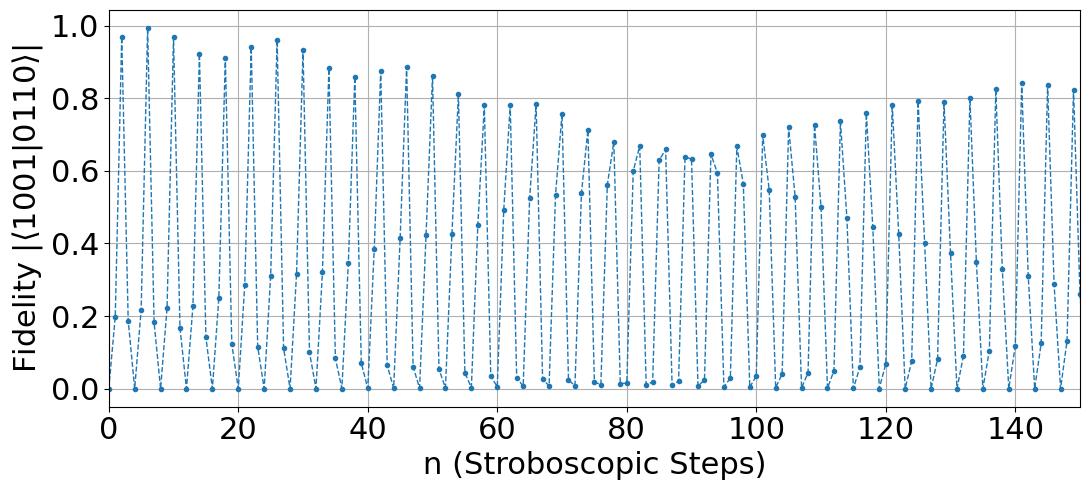

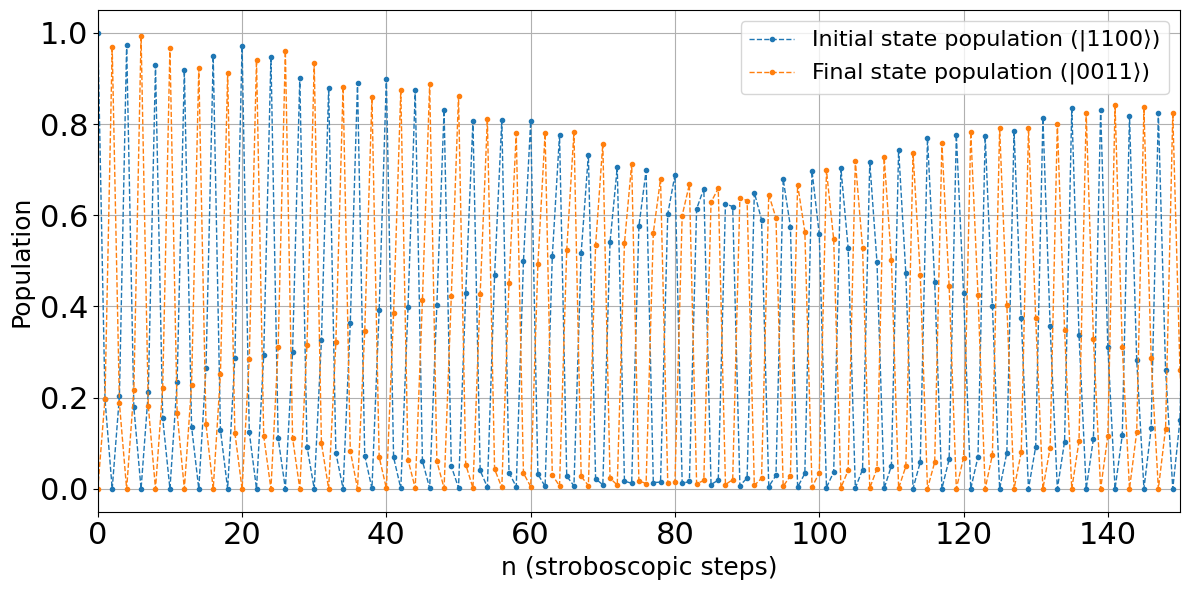

In [56]:
# === CELLA DI ANALISI E PLOT ===
# Da eseguire dopo la cella principale (funzioni già definite)

import numpy as np
import json
import matplotlib.pyplot as plt

# === CARICAMENTO DATI DAL FILE JSON GAUSSIANO ===
with open('1001_0110_gaussiano_sigma.json', 'r') as f:
    data = json.load(f)

omegas_opt = data['omegas_opt']
A_opt      = data['A_opt']
sigma_opt  = data['sigma_opt']
T_opt      = data['T_opt']
n_best     = data['n_opt']
couplings  = data['couplings']

print(f"Dati caricati: Fidelity attesa {data['fidelity']:.4f} a n={n_best}")
print(f"A={A_opt:.4f}, sigma={sigma_opt:.4f} "
      f"({'ottimizzata' if data['sigma_was_optimized'] else 'fissa'}), T={T_opt:.4f}")

# === RICOSTRUZIONE H0 E STATI ===
H0_opt = H0_7qubit(omegas_opt, couplings)

ket_source = np.zeros(128, dtype=complex); ket_source[65] = 1.0
ket_target = np.zeros(128, dtype=complex); ket_target[20] = 1.0

# === PRE-DIAGONALIZZAZIONE H0 (coerente con gaussian_kick_unitary_fast) ===
evals, evecs = np.linalg.eigh(H0_opt)
evecs_dag    = evecs.conj().T

# === PROPAGATORI ===
# Ufree via diagonalizzazione (niente expm)
phases_free = np.exp(-1j * evals * T_opt)
Ufree       = evecs @ (phases_free[:, None] * evecs_dag)

# Ukick via split operator (stessa funzione usata nell'ottimizzazione)
Ukick   = gaussian_kick_unitary_cpu(evals, evecs, evecs_dag, A_opt, sigma_opt)

Floquet = Ufree @ Ukick

# === EVOLUZIONE STROBOSCOPICA ===
Nplot = max(10000, int(n_best * 2))
ns    = np.arange(0, Nplot + 1)
fids, p_src, p_tgt = [], [], []

psi = ket_source.copy()
for n in ns:
    fids.append(np.abs(np.vdot(ket_target, psi))**2)
    p_src.append(np.abs(np.vdot(ket_source, psi))**2)
    p_tgt.append(np.abs(np.vdot(ket_target, psi))**2)
    psi = Floquet @ psi

# === SALVATAGGIO DATI ===
output_filename = 'evolution_data_7qubit_gaussian.txt'
print(f"Salvataggio dati in {output_filename}...")
with open(output_filename, 'w') as f:
    f.write("# Dati evoluzione 7-qubit con impulso GAUSSIANO\n")
    f.write(f"# omegas_opt={omegas_opt}\n")
    f.write(f"# A_opt={A_opt:.6f}, sigma_opt={sigma_opt:.6f}, "
            f"T_opt={T_opt:.4f}, n_best={n_best}\n")
    f.write("n   fidelity   popolazione_iniziale   popolazione_finale\n")
    for n, fid, p_s, p_t in zip(ns, fids, p_src, p_tgt):
        f.write(f"{n:<3} {fid:.8f}   {p_s:.8f}               {p_t:.8f}\n")
print(f"Salvato con successo in {output_filename}")

# === GRAFICI ===
sigma_str = f"σ={sigma_opt:.2f} ({'ott.' if data['sigma_was_optimized'] else 'fisso'})"

# Primo grafico: fidelity
plt.figure(figsize=(11, 5))
plt.plot(ns, fids, marker='o', markersize=3, linewidth=1,
         linestyle='--', label='Fidelity')
plt.xlabel('n (Stroboscopic Steps)', fontsize=22)
plt.ylabel('Fidelity ' r'$|\langle 1001|0110 \rangle|$', fontsize=22)
#plt.title(f'Fidelity stroboscopic evolution' , fontsize=24)
plt.grid(True)
#plt.legend(fontsize=16)
plt.xlim(0, 150)
plt.xticks(fontsize=22)
plt.yticks(fontsize=22)
plt.tight_layout()
plt.savefig('Fidelity_gaussian_1001-0110.pdf', format='pdf', bbox_inches='tight')
plt.show()

# Secondo grafico: popolazioni
plt.figure(figsize=(12, 6))
plt.plot(ns, p_src, marker='o', markersize=3, linewidth=1,
         linestyle='--', label='Initial state population (|1100⟩)')
plt.plot(ns, p_tgt, marker='o', markersize=3, linewidth=1,
         linestyle='--', label='Final state population (|0011⟩)')
plt.xlabel('n (stroboscopic steps)', fontsize=18)
plt.ylabel('Population', fontsize=18)
#plt.title(f'Populations: Initial vs Final — Gaussian kick\n'
          #f'A={A_opt:.3f}, {sigma_str}, T={T_opt:.3f}', fontsize=16)
plt.xlim(0, 150)
plt.xticks(fontsize=22)
plt.yticks(fontsize=22)
plt.legend(fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.savefig('Popolazioni_gaussian_1100-0011.pdf', format='pdf', bbox_inches='tight')
plt.show()

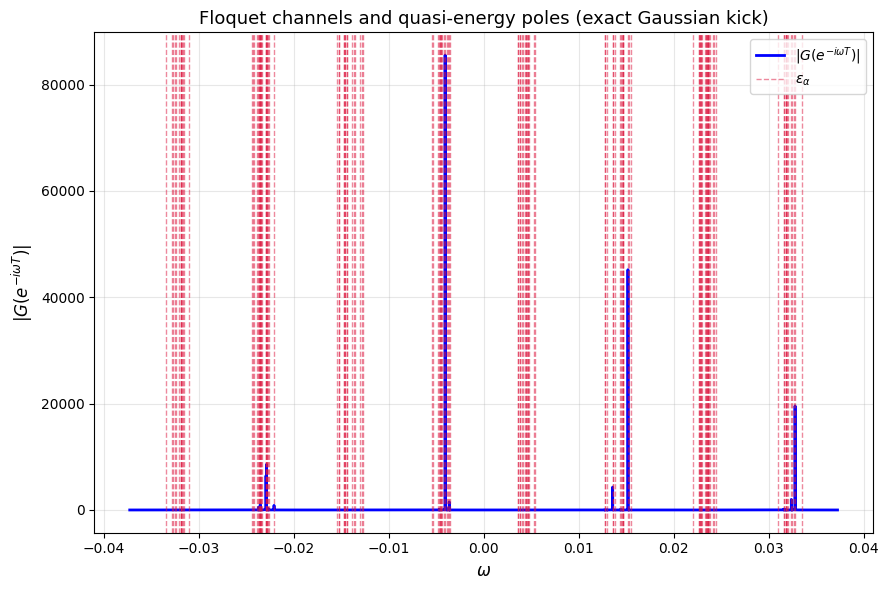

Unitarietà error (UF esatto): 6.65674299177894e-12
Residui dominanti: [0.21528499 0.20941189 0.20040732 0.19825531 0.03292717 0.03228835
 0.02928197 0.02796862 0.01341796 0.01271054]


In [46]:
# === CELLA: Risolvente e Quasi-energie (operatore di Floquet ESATTO, non impulsivo) ===
from scipy.linalg import eig

T = T_opt
dim = DIM  # 128

# USA L'OPERATORE DI FLOQUET VERO (Ufree @ Ukick_trotter), già calcolato
# nella cella di plot con la stessa gaussian_kick_unitary_cpu usata in ottimizzazione.
UF = Floquet   # <-- non più Ufree @ Kkick_delta

# === Autovalori e autovettori di UF ===
eigvals, eigvecs = eig(UF)
for j in range(dim):
    eigvecs[:, j] /= np.linalg.norm(eigvecs[:, j])

# === Quasi-energie ===
thetas = -np.angle(eigvals)
thetas = (thetas + np.pi) % (2 * np.pi) - np.pi
eps = thetas / T

# === Stati iniziale/finale ===
istate = ket_source
fstate = ket_target

# === Residui r_alpha ===
r = np.array([
    np.vdot(fstate, eigvecs[:, j]) * np.vdot(eigvecs[:, j], istate)
    for j in range(dim)
])

# === Resolvente ===
def Gofz(z):
    return np.sum(r / (1 - z * eigvals))

wmin, wmax, npts = -np.pi / T, np.pi / T, 100000
wgrid = np.linspace(wmin, wmax, npts)
Gvals = np.array([Gofz(np.exp(-1j * w * T)) for w in wgrid])
Gmag  = np.abs(Gvals)

plt.figure(figsize=(9, 6))
plt.plot(wgrid, Gmag, 'b-', lw=2, label=r'$|G(e^{-i\omega T})|$')
for i, e in enumerate(eps):
    plt.axvline(e, color='crimson', linestyle='--', lw=1, alpha=0.5,
                label=r'$\epsilon_\alpha$' if i == 0 else None)
plt.xlabel(r'$\omega$', fontsize=12)
plt.ylabel(r'$|G(e^{-i\omega T})|$', fontsize=12)
plt.title('Floquet channels and quasi-energy poles (exact Gaussian kick)', fontsize=13)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('Resolvente_7qubit_gaussian.pdf', format='pdf', bbox_inches='tight')
plt.show()

np.savetxt("floquet_eps_7qubit_gaussian.dat", eps)
np.savetxt("floquet_eps_7qubit_gaussian_sorted.dat", np.sort(eps))

unitarity_error = np.linalg.norm(UF.conj().T @ UF - np.eye(dim), np.inf)
print("Unitarietà error (UF esatto):", unitarity_error)
res_sorted = np.sort(np.abs(r))[::-1]
print("Residui dominanti:", res_sorted[:10])

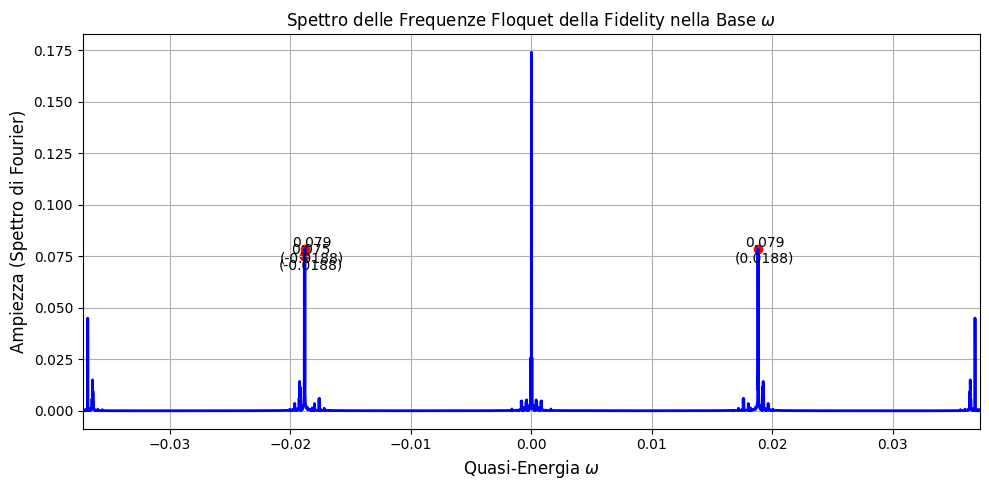


--- Analisi dello Spettro ---
  omega: 0.01880, Ampiezza: 0.07854
  omega: -0.01880, Ampiezza: 0.07854
  omega: -0.01885, Ampiezza: 0.07516


In [47]:
# === CELLA: FFT semplice della fidelity (base omega) ===
fidelity_data = np.array(fids)
N_data = len(fidelity_data)

fft_result = np.fft.fft(fidelity_data)
amplitude_spectrum = np.abs(fft_result) / N_data

freq_axis_nu = np.fft.fftfreq(N_data, d=1.0)
fft_shifted_nu = np.fft.fftshift(amplitude_spectrum)
freq_shifted_nu = np.fft.fftshift(freq_axis_nu)

omega_fft_axis = (2 * np.pi / T_opt) * freq_shifted_nu

plt.figure(figsize=(10, 5))
plt.plot(omega_fft_axis, fft_shifted_nu, 'b-', lw=2)

fft_shifted_display = fft_shifted_nu.copy()
zero_freq_idx = np.argmin(np.abs(omega_fft_axis))
fft_shifted_display[zero_freq_idx] = 0.0

peak_indices = np.argsort(fft_shifted_display)[::-1][:3]
peak_omegas = omega_fft_axis[peak_indices]
peak_amps = fft_shifted_nu[peak_indices]

for omega, amp in zip(peak_omegas, peak_amps):
    if amp > 0.01:
        plt.scatter(omega, amp, color='red', marker='o')
        plt.annotate(f'{amp:.3f}\n({omega:.4f})', (omega, amp),
                     textcoords="offset points", xytext=(5, -10), ha='center')

plt.title(r'Spettro delle Frequenze Floquet della Fidelity nella Base $\omega$')
plt.xlabel(r'Quasi-Energia $\omega$', fontsize=12)
plt.ylabel('Ampiezza (Spettro di Fourier)', fontsize=12)
plt.grid(True)
plt.xlim(-np.pi / T_opt, np.pi / T_opt)
plt.tight_layout()
plt.show()

print("\n--- Analisi dello Spettro ---")
for omega, amp in sorted(zip(peak_omegas, peak_amps), key=lambda x: x[1], reverse=True):
    if amp > 0.01:
        print(f"  omega: {omega:.5f}, Ampiezza: {amp:.5f}")

Risoluzione angolare Δω = 9.309013733705203e-07
Picchi trovati (omega, matched_eps_wrapped, original_eps, distanza):
4.095966e-05   3.576362e-03   3.576362e-03   diff = 3.535e-03
1.880607e-02   2.205530e-02   2.205530e-02   diff = 3.249e-03
1.884703e-02   2.205530e-02   2.205530e-02   diff = 3.208e-03
1.919891e-02   2.205530e-02   2.205530e-02   diff = 2.856e-03
1.924080e-02   2.205530e-02   2.205530e-02   diff = 2.814e-03
3.639173e-02   3.346765e-02   3.346765e-02   diff = 2.924e-03
3.643362e-02   3.346765e-02   3.346765e-02   diff = 2.966e-03
3.682646e-02   3.346765e-02   3.346765e-02   diff = 3.359e-03


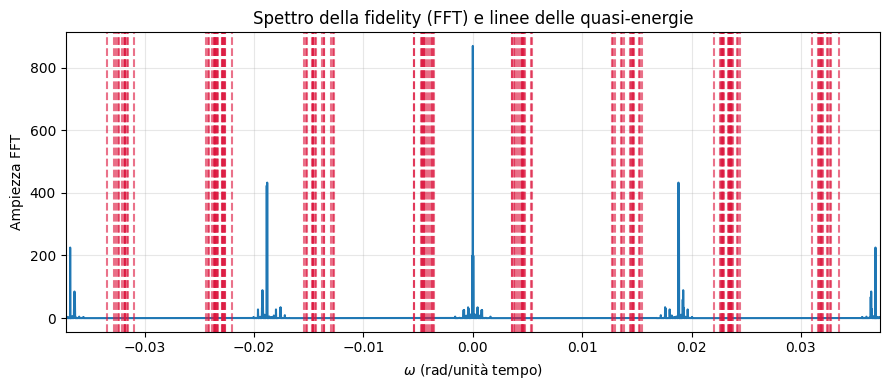

In [48]:
# === CELLA: FFT con finestratura + confronto con quasi-energie eps ===
from scipy.signal import find_peaks, windows

signal = np.array(fids)
N = signal.size
T = T_opt

win = windows.hann(N)
sig_win = signal * win

pad_factor = 8
Npad = int(N * pad_factor)
sig_pad = np.pad(sig_win, (0, Npad - N), mode='constant')

S = np.fft.fft(sig_pad)
freq_idx = np.fft.fftfreq(Npad, d=T)
omega_axis = 2 * np.pi * freq_idx
S_mag = np.abs(S)

omega_axis_shifted = np.fft.fftshift(omega_axis)
S_mag_shifted = np.fft.fftshift(S_mag)

half = Npad // 2
omega_pos = omega_axis_shifted[half:]
Spos = S_mag_shifted[half:]

peaks, props = find_peaks(Spos, height=np.max(Spos) * 0.05, distance=3)
peak_omegas = omega_pos[peaks]
peak_heights = props['peak_heights']

eps_wrapped = ((eps + np.pi / T) % (2 * np.pi / T)) - np.pi / T
matches = []
for om in peak_omegas:
    idx_closest = np.argmin(np.abs(eps_wrapped - om))
    matches.append((om, eps_wrapped[idx_closest], eps[idx_closest],
                     np.abs(eps_wrapped[idx_closest] - om)))

print("Risoluzione angolare Δω =", 2 * np.pi / (Npad * T))
print("Picchi trovati (omega, matched_eps_wrapped, original_eps, distanza):")
for m in matches:
    print(f"{m[0]:.6e}   {m[1]:.6e}   {m[2]:.6e}   diff = {m[3]:.3e}")

plt.figure(figsize=(9, 4))
plt.plot(omega_axis_shifted, S_mag_shifted, label='|FFT(signal)| (shifted)')
for e in eps:
    ewrap = ((e + np.pi / T) % (2 * np.pi / T)) - np.pi / T
    plt.axvline(ewrap, color='crimson', linestyle='--', alpha=0.6)
plt.xlim(-np.pi / T, np.pi / T)
plt.xlabel(r'$\omega$ (rad/unità tempo)')
plt.ylabel('Ampiezza FFT')
plt.title('Spettro della fidelity (FFT) e linee delle quasi-energie')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Top transizioni (a,b) con frequenza avvolta e peso:
(5,5)  Δε_wrapped = 0.000000e+00   peso = 4.635e-02
(5,34)  Δε_wrapped = -3.682663e-02   peso = 4.508e-02
(34,5)  Δε_wrapped = 3.682663e-02   peso = 4.508e-02
(34,34)  Δε_wrapped = 0.000000e+00   peso = 4.385e-02
(50,5)  Δε_wrapped = -1.884690e-02   peso = 4.314e-02
(5,50)  Δε_wrapped = 1.884690e-02   peso = 4.314e-02
(52,5)  Δε_wrapped = -1.880603e-02   peso = 4.268e-02
(5,52)  Δε_wrapped = 1.880603e-02   peso = 4.268e-02
(34,50)  Δε_wrapped = -1.880603e-02   peso = 4.197e-02
(50,34)  Δε_wrapped = 1.880603e-02   peso = 4.197e-02
(34,52)  Δε_wrapped = -1.884690e-02   peso = 4.152e-02
(52,34)  Δε_wrapped = 1.884690e-02   peso = 4.152e-02
(50,50)  Δε_wrapped = 0.000000e+00   peso = 4.016e-02
(50,52)  Δε_wrapped = -4.087234e-05   peso = 3.973e-02
(52,50)  Δε_wrapped = 4.087234e-05   peso = 3.973e-02
(52,52)  Δε_wrapped = 0.000000e+00   peso = 3.931e-02
(5,28)  Δε_wrapped = -3.639143e-02   peso = 7.089e-03
(28,5)  Δε_wrapped = 3.639143e-0

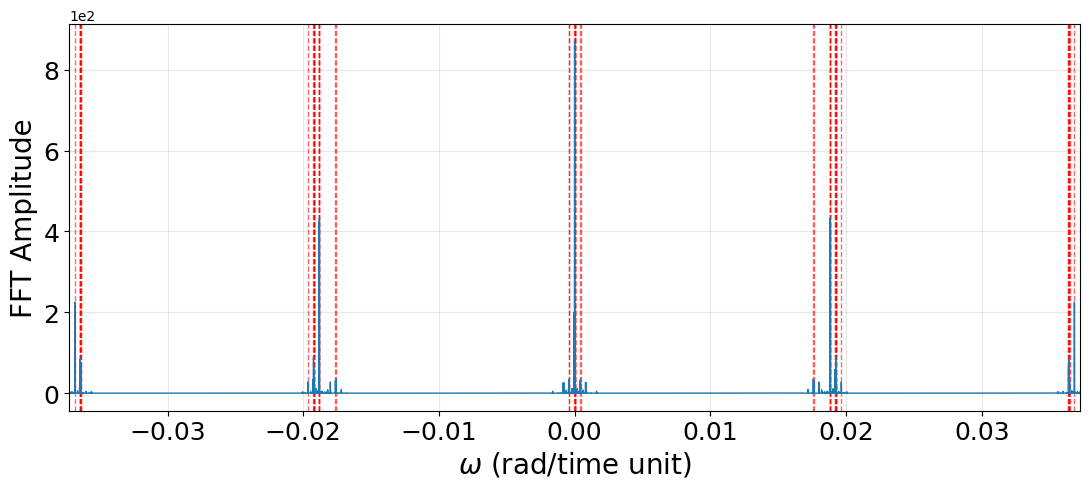

In [51]:
# === CELLA: transizioni Δε pesate dai residui, sovrapposte allo spettro ===
dim = eps.size

c = np.array([np.vdot(eigvecs[:, a], ket_source) for a in range(dim)])
d = np.array([np.vdot(ket_target, eigvecs[:, a]) for a in range(dim)])

DE, WE, pairs = [], [], []
for a in range(dim):
    for b in range(dim):
        delta = eps[a] - eps[b]
        delta_wrapped = ((delta + np.pi / T) % (2 * np.pi / T)) - np.pi / T
        weight = np.abs(c[a] * np.conj(c[b]) * d[b] * np.conj(d[a]))
        DE.append(delta_wrapped)
        WE.append(weight)
        pairs.append((a, b))

DE = np.array(DE)
WE = np.array(WE)

topK = 50
idx_sorted = np.argsort(WE)[::-1]
top_idx = idx_sorted[:topK]

print("Top transizioni (a,b) con frequenza avvolta e peso:")
for ii in top_idx:
    a, b = pairs[ii]
    print(f"({a},{b})  Δε_wrapped = {DE[ii]:.6e}   peso = {WE[ii]:.3e}")

plt.figure(figsize=(11, 5))
for ii in top_idx:
    plt.axvline(DE[ii], color='red', linestyle='--', linewidth=1, alpha=0.6)
plt.plot(omega_axis_shifted, S_mag_shifted, lw=1, color='tab:blue')
plt.xlim(-np.pi / T, np.pi / T)
plt.xlabel(r'$\omega$ (rad/time unit)', fontsize=20)
plt.ylabel('FFT Amplitude', fontsize=20)
#plt.title('Spectrum with weighted Δε transitions (dashed lines)', fontsize=22)
plt.grid(alpha=0.3)
ax = plt.gca()
ax.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.tight_layout()
plt.savefig('confronto_gaussiano_1100-0011.pdf', format='pdf', bbox_inches='tight')
plt.show()